# Coletando dados sem rótulo\n
\n
Projeto de clusterização para identificar padrões e segmentar consumidores por áreas de interesse.

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

ImportError: Unable to import required dependency numpy. Please see the traceback for details.

In [ ]:
url = 'https://raw.githubusercontent.com/Mirlaa/Clusterizacao-dados-sem-rotulo/main/Dados/dados_mkt.csv'

In [2]:
df = pd.read_csv(url)

df

NameError: name 'pd' is not defined

In [3]:
df.info()

NameError: name 'df' is not defined

In [4]:
df['sexo'].unique()

NameError: name 'df' is not defined

In [5]:
from sklearn.preprocessing import OneHotEncoder



encoder = OneHotEncoder(categories=[['NE', 'F', 'M']], sparse_output=False)

ImportError: No module named 'sklearn.__check_build._check_build'
___________________________________________________________________________
Contents of C:\Users\rafal\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\__check_build:
meson.build               _check_build.cp314-win_amd64.lib_check_build.cp314-win_amd64.pyd
_check_build.pyx          __init__.py               __pycache__
___________________________________________________________________________
It seems that scikit-learn has not been built correctly.

If you have installed scikit-learn from source, please do not forget
to build the package before using it. For detailed instructions, see:
https://scikit-learn.org/dev/developers/advanced_installation.html#building-from-source

If you have used an installer, please check that it is suited for your
Python version, your operating system and your platform.

In [6]:
encoded_sexo = encoder.fit_transform(df[['sexo']])
encoded_sexo

NameError: name 'encoder' is not defined

In [7]:
encoded_df = pd.DataFrame(encoded_sexo, columns=encoder.get_feature_names_out(['sexo']))

NameError: name 'pd' is not defined

In [8]:
dados = pd.concat([df, encoded_df], axis=1).drop('sexo', axis=1)
dados

NameError: name 'pd' is not defined

In [9]:
import joblib

joblib.dump(encoder, 'encoder.pkl')

NameError: name 'encoder' is not defined

In [11]:
from sklearn.cluster import KMeans

In [12]:
mod_kmeans = KMeans(n_clusters=2, random_state=45)

In [13]:
modelo = mod_kmeans.fit(dados)

C:\Users\rafal\Desktop\projeto-aula\.venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\rafal\Desktop\projeto-aula\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\rafal\Desktop\projeto-aula\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\rafal\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", 

In [14]:
mod_kmeans.inertia_

24912957.594588574

In [15]:
from sklearn.metrics import silhouette_score

In [16]:
silhouette_score(dados, mod_kmeans.predict(dados))

0.3799715886302017

In [17]:
def avaliacao(dados):
    inercia = []
    silhueta = []

    for k in range(2, 21):
        kmeans = KMeans(n_clusters=k, random_state=45, n_init='auto')
        kmeans.fit(dados)
        inercia.append(kmeans.inertia_)
        silhueta.append(f'k={k} - ' + str(silhouette_score(dados, kmeans.predict(dados))))

    return silhueta, inercia


In [18]:
from sklearn.preprocessing import StandardScaler
escalonador = StandardScaler()
dados_escalados = pd.DataFrame(
    escalonador.fit_transform(dados),
    columns=dados.columns,
    index=dados.index
)
dados_escalados.describe()


,idade,numero_de_amigos,basquete,futebol_americano,futebol,softbol,voleibol,natacao,animacao,beisebol,...,vestido,shopping,compras,roupas,nossa_marca,marca_concorrente,bebidas,sexo_NE,sexo_F,sexo_M
count,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,...,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04,1.299200e+04
mean,-1.274295e-15,1.859487e-17,1.421961e-17,-9.297434e-18,1.668069e-17,-3.937737e-17,2.953303e-17,3.281447e-17,5.359697e-17,-3.281447e-18,...,7.656711e-18,1.039125e-17,-3.281447e-18,-2.515776e-17,3.007993e-18,-3.172066e-17,3.472865e-17,-1.312579e-17,-5.305007e-17,5.195625e-17
std,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,...,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00,1.000038e+00
min,-4.862240e+00,-8.716625e-01,-3.658203e-01,-3.939254e-01,-2.585996e-01,-2.330241e-01,-2.406721e-01,-2.641848e-01,-2.246208e-01,-2.155957e-01,...,-2.715585e-01,-3.981884e-01,-5.338583e-01,-3.378471e-01,-2.157397e-01,-1.965684e-01,-2.338905e-01,-2.791163e-01,-1.786706e+00,-4.465525e-01
25%,-7.083813e-01,-7.323471e-01,-3.658203e-01,-3.939254e-01,-2.585996e-01,-2.330241e-01,-2.406721e-01,-2.641848e-01,-2.246208e-01,-2.155957e-01,...,-2.715585e-01,-3.981884e-01,-5.338583e-01,-3.378471e-01,-2.157397e-01,-1.965684e-01,-2.338905e-01,-2.791163e-01,5.596890e-01,-4.465525e-01
50%,1.223905e-01,-2.865380e-01,-3.658203e-01,-3.939254e-01,-2.585996e-01,-2.330241e-01,-2.406721e-01,-2.641848e-01,-2.246208e-01,-2.155957e-01,...,-2.715585e-01,-3.981884e-01,-5.338583e-01,-3.378471e-01,-2.157397e-01,-1.965684e-01,-2.338905e-01,-2.791163e-01,5.596890e-01,-4.465525e-01
75%,9.531623e-01,3.821758e-01,-3.658203e-01,-3.939254e-01,-2.585996e-01,-2.330241e-01,-2.406721e-01,-2.641848e-01,-2.246208e-01,-2.155957e-01,...,-2.715585e-01,-3.981884e-01,7.698799e-01,-3.378471e-01,-2.157397e-01,-1.965684e-01,-2.338905e-01,-2.791163e-01,5.596890e-01,-4.465525e-01
max,2.614706e+00,1.598550e+01,2.590559e+01,1.171780e+01,2.216675e+01,2.133723e+01,2.029187e+01,5.261899e+01,1.465504e+01,2.497019e+01,...,1.391375e+01,1.564709e+01,1.380726e+01,1.537333e+01,2.083884e+01,2.647515e+01,1.757537e+01,3.582736e+00,5.596890e-01,2.239378e+00


In [19]:
silhueta, inercia = avaliacao(dados_escalados)
silhueta

['k=2 - 0.2861687801850292',
 'k=3 - 0.14513581742459042',
 'k=4 - 0.14843797233273107',
 'k=5 - 0.17506150214417848',
 'k=6 - 0.17738970340671564',
 'k=7 - 0.16923279688079104',
 'k=8 - 0.170843482720174',
 'k=9 - 0.08835967320616729',
 'k=10 - 0.07263745700639981',
 'k=11 - 0.07767530890108149',
 'k=12 - 0.07936139440292084',
 'k=13 - 0.08393283833089046',
 'k=14 - 0.07944299565817452',
 'k=15 - 0.08366584508255769',
 'k=16 - 0.08556560144108119',
 'k=17 - 0.09386280349713837',
 'k=18 - 0.09628725109157396',
 'k=19 - 0.09317153892542013',
 'k=20 - 0.0864433640589261']

In [20]:
import matplotlib.cm as cm
from sklearn.metrics import silhouette_samples

def graf_silhueta(n_clusters, dados):

    # Aplica o KMeans ao conjunto de dados
    kmeans = KMeans(n_clusters=n_clusters, random_state=45, n_init='auto')
    cluster_previsoes = kmeans.fit_predict(dados)

    # Calcula o silhouette score m?dio
    silhueta_media = silhouette_score(dados, cluster_previsoes)
    print(f'Valor m?dio para {n_clusters} clusters: {silhueta_media:.3f}')

    # Calcula a pontua??o de silhueta para cada amostra
    silhueta_amostra = silhouette_samples(dados, cluster_previsoes)

    # Configura??o da figura para o gr?fico de silhueta
    fig, ax1 = plt.subplots(1, 1)
    fig.set_size_inches(9, 7)

    # Limites do gr?fico de silhueta
    ax1.set_xlim([-0.1, 1])
    ax1.set_ylim([0, len(dados) + (n_clusters + 1) * 10])

    y_lower = 10
    for i in range(n_clusters):
        ith_cluster_silhueta_amostra = silhueta_amostra[cluster_previsoes == i]
        ith_cluster_silhueta_amostra.sort()

        tamanho_cluster_i = ith_cluster_silhueta_amostra.shape[0]
        y_upper = y_lower + tamanho_cluster_i

        cor = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhueta_amostra,
            facecolor=cor,
            edgecolor=cor,
            alpha=0.7
        )

        ax1.text(-0.05, y_lower + 0.5 * tamanho_cluster_i, str(i))
        y_lower = y_upper + 10  # 10 para o espa?o entre gr?ficos

    # Linha vertical para a m?dia do Silhouette Score
    ax1.axvline(x=silhueta_media, color='red', linestyle='--')

    ax1.set_title(f'Gr?fico da Silhueta para {n_clusters} clusters')
    ax1.set_xlabel('Valores do coeficiente de silhueta')
    ax1.set_ylabel('R?tulo do cluster')

    ax1.set_yticks([])
    ax1.set_xticks([i / 10.0 for i in range(-1, 11)])

    plt.show()


In [21]:
graf_silhueta(3, dados_escalados)


Valor m?dio para 3 clusters: 0.145


<Figure size 900x700 with 1 Axes>

In [ ]:
def plot_cotovelo(inercia):
    import matplotlib.pyplot as plt

    valores_k = range(2, len(inercia) + 2)
    plt.plot(valores_k, inercia, marker="o")
    plt.xlabel("Numero de clusters (K)")
    plt.ylabel("Inercia")
    plt.title("Metodo do cotovelo")
    plt.xticks(list(valores_k))
    plt.grid(True)
    plt.show()


In [22]:
plot_cotovelo(inercia)

modelo_kmeans = KMeans(n_clusters=3, random_state=45, n_init='auto')
modelo_kmeans.fit(dados_escalados)

joblib.dump(modelo_kmeans, 'kmeans.pkl')


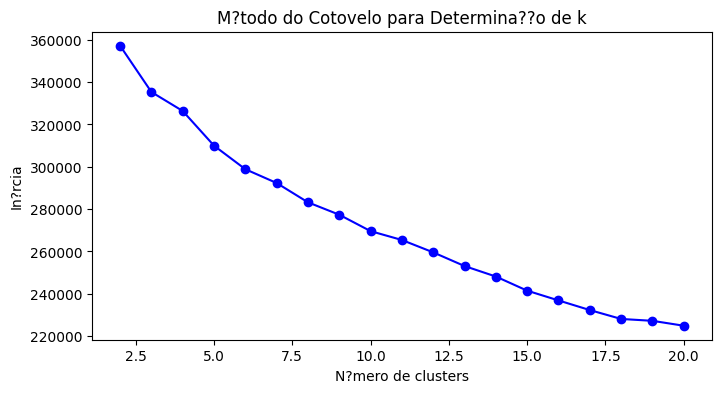

In [23]:
plot_cotovelo(inercia)


In [24]:
from sklearn.cluster import KMeans
modelo_kmeans = KMeans(n_clusters=3, random_state=45, n_init='auto')
modelo_kmeans.fit(dados_escalados)

KMeans(n_clusters=3, n_init='auto', random_state=45)

In [25]:
joblib.dump(modelo_kmeans, 'kmeans.pkl')

['kmeans.pkl']

In [26]:
dados_analise = pd.DataFrame()

dados_analise[dados_escalados.columns] = escalonador.inverse_transform(dados_escalados)

dados_analise

,idade,numero_de_amigos,basquete,futebol_americano,futebol,softbol,voleibol,natacao,animacao,beisebol,...,vestido,shopping,compras,roupas,nossa_marca,marca_concorrente,bebidas,sexo_NE,sexo_F,sexo_M
0,27.0,49.0,0.0,0.0,10.0,0.0,0.0,1.000000e+01,0.0,0.0,...,-2.220446e-16,0.0,0.0,0.0,0.0,0.0,10.0,0.0,1.0,0.0
1,27.0,41.0,0.0,0.0,0.0,0.0,0.0,2.220446e-16,0.0,10.0,...,-2.220446e-16,10.0,0.0,0.0,0.0,0.0,10.0,0.0,1.0,0.0
2,26.0,1.0,0.0,0.0,0.0,0.0,0.0,1.000000e+01,0.0,0.0,...,-2.220446e-16,0.0,0.0,30.0,0.0,0.0,0.0,0.0,1.0,0.0
3,28.0,32.0,0.0,50.0,0.0,0.0,0.0,2.220446e-16,0.0,0.0,...,-2.220446e-16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,28.0,18.0,0.0,0.0,0.0,0.0,0.0,2.220446e-16,0.0,0.0,...,-2.220446e-16,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12987,26.0,21.0,0.0,0.0,0.0,0.0,0.0,2.220446e-16,0.0,0.0,...,-2.220446e-16,0.0,0.0,20.0,0.0,0.0,0.0,0.0,1.0,0.0
12988,26.0,50.0,0.0,0.0,0.0,0.0,0.0,2.220446e-16,0.0,10.0,...,-2.220446e-16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
12989,27.0,32.0,0.0,0.0,0.0,0.0,0.0,2.220446e-16,10.0,0.0,...,-2.220446e-16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
12990,27.0,20.0,0.0,0.0,0.0,0.0,0.0,2.220446e-16,0.0,0.0,...,-2.220446e-16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [27]:
dados_analise['cluster'] = modelo_kmeans.labels_

In [28]:
cluster_media = dados_analise.groupby('cluster').mean()

cluster,0,1,2
idade,26.880135,27.036744,26.525805
numero_de_amigos,30.314350,26.057674,41.426673
basquete,2.052898,3.762791,6.882984
futebol_americano,1.663478,5.386047,5.963209
futebol,2.025886,2.544186,4.849259
softbol,1.691615,0.093023,4.409811
voleibol,1.286438,0.446512,4.563107
natacao,1.261677,0.986047,3.469596
animacao,0.885763,0.088372,3.898825
beisebol,0.492966,3.283721,2.110373


In [29]:
cluster_media = cluster_media.transpose()

cluster_media.columns = [0, 1, 2]

In [30]:
cluster_media

,0,1,2
idade,26.880135,27.036744,26.525805
numero_de_amigos,30.314350,26.057674,41.426673
basquete,2.052898,3.762791,6.882984
futebol_americano,1.663478,5.386047,5.963209
futebol,2.025886,2.544186,4.849259
softbol,1.691615,0.093023,4.409811
voleibol,1.286438,0.446512,4.563107
natacao,1.261677,0.986047,3.469596
animacao,0.885763,0.088372,3.898825
beisebol,0.492966,3.283721,2.110373


In [31]:
cluster_media[0].sort_values(ascending=False)

numero_de_amigos     30.314350
idade                26.880135
musica                7.072594
danca                 3.864941
compras               3.484524
fofo                  3.070343
cabelo                2.963421
banda                 2.799100
shopping              2.090039
basquete              2.052898
futebol               2.025886
rock                  1.995498
softbol               1.691615
futebol_americano     1.663478
voleibol              1.286438
natacao               1.261677
esportes              0.967923
roupas                0.918402
sexo_F                0.906134
animacao              0.885763
vestido               0.858751
tenis                 0.844119
bebidas               0.710186
beisebol              0.492966
marcha                0.416432
nossa_marca           0.305008
marca_concorrente     0.175577
sexo_NE               0.093866
sexo_M                0.000000
Name: 0, dtype: float64

In [32]:
cluster_media[1].sort_values(ascending=False)

idade                27.036744
numero_de_amigos     26.057674
musica                7.995349
futebol_americano     5.386047
banda                 3.897674
basquete              3.762791
beisebol              3.283721
rock                  2.911628
futebol               2.544186
danca                 2.544186
esportes              2.353488
cabelo                1.795349
shopping              1.493023
tenis                 1.302326
sexo_M                0.996744
natacao               0.986047
bebidas               0.920930
fofo                  0.813953
roupas                0.758140
compras               0.493023
marcha                0.488372
voleibol              0.446512
nossa_marca           0.358140
vestido               0.358140
marca_concorrente     0.232558
softbol               0.093023
animacao              0.088372
sexo_NE               0.003256
sexo_F                0.000000
Name: 1, dtype: float64

In [33]:
cluster_media[2].sort_values(ascending=False)

numero_de_amigos     41.426673
idade                26.525805
cabelo               17.317322
musica               14.721513
danca                12.401635
compras              10.822688
fofo                 10.158406
shopping              8.640777
basquete              6.882984
roupas                6.417987
rock                  6.290240
futebol_americano     5.963209
banda                 5.907001
futebol               4.849259
vestido               4.603986
voleibol              4.563107
softbol               4.409811
esportes              3.914154
animacao              3.898825
nossa_marca           3.663771
natacao               3.469596
marca_concorrente     2.861523
bebidas               2.738886
beisebol              2.110373
tenis                 1.425652
sexo_F                0.941237
marcha                0.786919
sexo_NE               0.050077
sexo_M                0.008687
Name: 2, dtype: float64

In [34]:
print(inercia)

[357220.1149016354, 335349.27406539506, 326376.0977171954, 309985.0728997393, 298858.02560832305, 292337.33970449294, 283214.8222364063, 277347.7648519772, 269593.3484173057, 265405.8392571019, 259559.71418923466, 253098.0615377161, 248141.08346301178, 241461.45871183346, 236848.7664743974, 232297.22771109725, 228094.3158035311, 227206.71543376343, 224892.2677321624]


In [ ]:
plot_cotovelo(inercia)

modelo_kmeans = KMeans(n_clusters=3, random_state=45, n_init='auto')
modelo_kmeans.fit(dados_escalados)

joblib.dump(modelo_kmeans, 'kmeans.pkl')


In [ ]:
dados["cluster"] = modelo_kmeans.predict(dados_escalados)
dados.groupby("cluster").mean(numeric_only=True)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(dados, hue='cluster', diag_kind='hist')
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

silhueta = silhouette_score(dados_escalados, modelo_kmeans.labels_)
print(f'Silhueta m?dia: {silhueta:.3f}')


In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
dados['gender_encoded'] = encoder.fit_transform(dados['gender'])

joblib.dump(encoder, 'encoder.pkl')
dados[['gender', 'gender_encoded']].head()


In [ ]:
print('Quantidade de registros por cluster:')
print(dados['cluster'].value_counts().sort_index())

print('\nM?dias das vari?veis num?ricas por cluster:')
dados.groupby('cluster').mean(numeric_only=True).round(2)


In [ ]:
centros_originais = scaler.inverse_transform(modelo_kmeans.cluster_centers_)

perfil_clusters = pd.DataFrame(
    centros_originais,
    columns=colunas_numericas
).round(2)

perfil_clusters.index.name = 'cluster'
perfil_clusters


In [ ]:
dados.to_csv('dados_com_clusters.csv', index=False)
print("Dados com os clusters salvos em 'dados_com_clusters.csv'.")


In [ ]:
novo_dado = pd.DataFrame([{
    'idade': 26,
    'numero_de_amigos': 2,
    'basquete': 3,
    'futebol_americano': 0,
    'futebol_soccer': 1,
    'gender_encoded': encoder.transform(['F'])[0]
}])

novo_dado = novo_dado[colunas_numericas]
novo_dado_escalado = scaler.transform(novo_dado)
cluster_previsto = modelo_kmeans.predict(novo_dado_escalado)[0]

print(f'O novo registro foi atribu?do ao cluster {cluster_previsto}.')


In [ ]:
print(f'Cluster previsto: {cluster_previsto}')
print('Perfil m?dio desse cluster:')
display(perfil_clusters.loc[cluster_previsto])


In [ ]:
import os
import joblib

arquivos_modelo = ['kmeans.pkl', 'scaler.pkl', 'encoder.pkl']

for nome in arquivos_modelo:
    print(f'{nome}: {"encontrado" if os.path.exists(nome) else "n?o encontrado"}')

modelo_carregado = joblib.load('kmeans.pkl')
scaler_carregado = joblib.load('scaler.pkl')
encoder_carregado = joblib.load('encoder.pkl')

print('Modelos e transformadores carregados com sucesso.')


In [ ]:
dados_escalados_carregados = scaler_carregado.transform(dados[colunas_numericas])
clusters_recalculados = modelo_carregado.predict(dados_escalados_carregados)

percentual_igual = (clusters_recalculados == dados['cluster'].to_numpy()).mean() * 100
print(f'Previs?es iguais aos clusters originais: {percentual_igual:.1f}%')


In [ ]:
print('Resumo final do projeto:')
print(f'Quantidade de registros: {len(dados)}')
print(f'Quantidade de clusters: {dados["cluster"].nunique()}')
print(f'Silhueta m?dia: {silhouette_score(dados_escalados, modelo_kmeans.labels_):.3f}')
print('Arquivos do modelo: kmeans.pkl, scaler.pkl e encoder.pkl')


In [ ]:
print('Conclus?o:')
print('O KMeans agrupou os registros por semelhan?a nas vari?veis utilizadas.')
print('Os n?meros dos clusters s?o r?tulos de grupos, n?o categorias com ordem ou significado fixo.')
print('Use o perfil de cada cluster para interpretar as caracter?sticas dos grupos.')


In [ ]:
# Exerc?cio: classifique um novo registro
# Altere os valores abaixo e compare o cluster previsto.

novo_dado = pd.DataFrame([{
    'idade': 30,
    'numero_de_amigos': 4,
    'basquete': 1,
    'futebol_americano': 2,
    'futebol_soccer': 3,
    'gender_encoded': encoder.transform(['M'])[0]
}])

novo_dado = novo_dado[colunas_numericas]
novo_dado_escalado = scaler.transform(novo_dado)
cluster_previsto = modelo_kmeans.predict(novo_dado_escalado)[0]

print(f'Cluster previsto para o novo registro: {cluster_previsto}')


## Interpreta??o e limite do modelo

O KMeans atribui o novo registro ao centroide mais pr?ximo, usando as vari?veis escalonadas. O n?mero do cluster ? apenas um identificador: cluster 0 n?o ? melhor nem maior que cluster 1.

A coluna `gender` foi convertida em n?meros pelo `LabelEncoder`. Como esses n?meros podem criar uma ordem artificial entre categorias, trate o resultado com cautela: o agrupamento pode ser influenciado por essa codifica??o. Em uma an?lise real, avalie uma codifica??o adequada para categorias, como one-hot encoding, e compare os resultados.


In [ ]:
# Teste com um registro de exemplo da tabela
registro_exemplo = pd.DataFrame([{
    'idade': 26,
    'numero_de_amigos': 2,
    'basquete': 3,
    'futebol_americano': 0,
    'futebol_soccer': 1,
    'gender_encoded': encoder.transform(['F'])[0]
}])

registro_exemplo = registro_exemplo[colunas_numericas]
registro_escalado = scaler.transform(registro_exemplo)
cluster_exemplo = modelo_kmeans.predict(registro_escalado)[0]

print(f'O registro de exemplo foi atribu?do ao cluster {cluster_exemplo}.')


In [ ]:
# Compare os clusters previstos para os registros da tabela
registros_teste = dados[colunas_numericas].copy()
registros_teste_escalados = scaler.transform(registros_teste)
clusters_previstos = modelo_kmeans.predict(registros_teste_escalados)

comparacao = dados[['idade', 'numero_de_amigos', 'gender', 'cluster']].copy()
comparacao['cluster_previsto'] = clusters_previstos

display(comparacao.head(10))


In [ ]:
# Verifique se as previs?es reproduzem os clusters j? registrados
acuracia_rotulos = (
    comparacao['cluster'] == comparacao['cluster_previsto']
).mean()

print(f'Registros com o mesmo r?tulo de cluster: {acuracia_rotulos:.1%}')
display(pd.crosstab(
    comparacao['cluster'],
    comparacao['cluster_previsto'],
    rownames=['Cluster original'],
    colnames=['Cluster previsto']
))


## Como interpretar a tabela de compara??o

As linhas mostram os clusters originais e as colunas mostram os clusters previstos pelo modelo carregado. Os valores indicam quantos registros ca?ram em cada combina??o.

Se os r?tulos forem iguais, os registros aparecem na diagonal da tabela. Como o modelo foi salvo e carregado, a compara??o deve coincidir quando os dados, a ordem das colunas e o pr?-processamento forem os mesmos. Os n?meros dos clusters s?o identificadores, n?o categorias ordenadas.


In [ ]:
# Analise o tamanho e o perfil de cada cluster
tamanho_clusters = dados['cluster'].value_counts().sort_index()
percentual_clusters = (tamanho_clusters / len(dados) * 100).round(1)

resumo_clusters = pd.DataFrame({
    'quantidade': tamanho_clusters,
    'percentual': percentual_clusters
})

display(resumo_clusters)
display(dados.groupby('cluster')[colunas_numericas].mean().round(2))


In [ ]:
# Visualize a quantidade de registros em cada cluster
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
sns.countplot(data=dados, x='cluster', hue='cluster', legend=False)
plt.title('Quantidade de registros por cluster')
plt.xlabel('Cluster')
plt.ylabel('Quantidade de registros')
plt.tight_layout()
plt.show()


In [ ]:
# Visualize os clusters por idade e numero de amigos
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=dados,
    x='idade',
    y='numero_de_amigos',
    hue='cluster',
    palette='Set1',
    s=100
)

plt.title('Clusters por idade e numero de amigos')
plt.xlabel('Idade')
plt.ylabel('Numero de amigos')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()


In [ ]:
# Compare a distribuicao das variaveis numericas por cluster
import seaborn as sns
import matplotlib.pyplot as plt

variaveis = [
    'idade',
    'numero_de_amigos',
    'basquete',
    'futebol_americano',
    'futebol_soccer'
]

fig, eixos = plt.subplots(1, len(variaveis), figsize=(18, 4))

for eixo, variavel in zip(eixos, variaveis):
    sns.boxplot(
        data=dados,
        x='cluster',
        y=variavel,
        hue='cluster',
        palette='Set1',
        ax=eixo
    )
    if eixo.legend_ is not None:
        eixo.legend_.remove()
    eixo.set_title(variavel.replace('_', ' ').title())
    eixo.set_xlabel('Cluster')
    eixo.set_ylabel('Valor')

plt.tight_layout()
plt.show()


In [ ]:
# Visualize o perfil medio padronizado dos clusters
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

dados_padronizados = pd.DataFrame(
    scaler.transform(dados[colunas_numericas]),
    columns=colunas_numericas,
    index=dados.index
)
dados_padronizados['cluster'] = dados['cluster']

perfil_padronizado = dados_padronizados.groupby('cluster').mean()

plt.figure(figsize=(10, 5))
sns.heatmap(
    perfil_padronizado,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)
plt.title('Perfil medio padronizado por cluster')
plt.xlabel('Variaveis')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()


## Como interpretar o mapa de calor

Os valores mostram a m?dia de cada vari?vel em cada cluster ap?s a padroniza??o. Valores acima de zero indicam m?dias superiores ? m?dia geral daquela vari?vel; valores abaixo de zero indicam m?dias inferiores. Quanto mais distante de zero, maior a diferen?a relativa.

Use o mapa para comparar os perfis dos grupos, junto com as quantidades e os gr?ficos anteriores. A padroniza??o facilita comparar vari?veis em escalas diferentes, mas n?o altera o significado das vari?veis nem prova que os grupos sejam categorias naturais.


In [ ]:
# Compare as medias originais das variaveis por cluster
medias_originais = dados.groupby('cluster')[colunas_numericas].mean().round(2)
display(medias_originais)


## Interpretacao das medias originais

Esta tabela mostra a media de cada variavel em cada cluster nas unidades originais dos dados. Compare os valores entre as linhas para identificar quais caracter?sticas diferenciam os grupos.

Por exemplo, se um cluster tiver media maior em `numero_de_amigos`, os registros daquele grupo tendem a ter mais amigos na amostra. As medias resumem os grupos, mas nao representam necessariamente cada pessoa dentro deles.


In [ ]:
# Resuma as variaveis numericas por cluster
resumo_clusters = dados.groupby('cluster')[colunas_numericas].agg(
    ['count', 'mean', 'min', 'max']
).round(2)

display(resumo_clusters)


In [ ]:
# Confira as colunas usadas pelo modelo
print("Colunas numericas:", colunas_numericas)
print("Colunas existentes em dados:", dados.columns.tolist())

# Verifique se todas as colunas numericas esperadas estao no DataFrame
colunas_ausentes = [
    coluna for coluna in colunas_numericas
    if coluna not in dados.columns
]

if colunas_ausentes:
    print("Colunas ausentes em dados:", colunas_ausentes)
else:
    print("Todas as colunas numericas esperadas estao presentes.")


In [ ]:
# Valide as colunas antes das analises por cluster
if colunas_ausentes:
    raise ValueError(
        f"Faltam no DataFrame as colunas necessarias: {colunas_ausentes}"
    )

print("Validacao concluida: as colunas necessarias estao presentes.")


In [ ]:
# Verifique a estrutura e os valores ausentes dos dados
print("Dimensoes do conjunto de dados:", dados.shape)
print("\nTipos de dados:")
display(dados.dtypes.to_frame(name='tipo_de_dado'))

print("\nValores ausentes por coluna:")
display(dados.isna().sum().to_frame(name='valores_ausentes'))

print("\nResumo das variaveis:")
display(dados.describe(include='all').T)


In [ ]:
# Confira o balanceamento dos clusters
contagem_clusters = dados['cluster'].value_counts().sort_index()
percentual_clusters = (
    dados['cluster'].value_counts(normalize=True).sort_index() * 100
).round(2)

resumo_balanceamento = contagem_clusters.to_frame(name='quantidade')
resumo_balanceamento['percentual'] = percentual_clusters

display(resumo_balanceamento)


## Interpretacao do balanceamento dos clusters

A tabela apresenta a quantidade e a porcentagem de registros atribu?dos a cada cluster. Percentuais muito diferentes mostram que os grupos t?m tamanhos desiguais, mas isso, por si s?, n?o significa que o resultado esteja errado.

Interprete o balanceamento junto com o perfil das vari?veis e a distribui??o dos dados. Os r?tulos dos clusters s?o identificadores: cluster 0, por exemplo, n?o ? necessariamente melhor ou menor que cluster 1.


In [ ]:
# Mostre os registros agrupados por cluster
colunas_exibicao = [
    coluna for coluna in [
        'idade',
        'numero_de_amigos',
        'basquete',
        'futebol_americano',
        'futebol_soccer',
        'gender',
        'cluster'
    ]
    if coluna in dados.columns
]

for identificador, grupo in dados.groupby('cluster', sort=True):
    print(f"Cluster {identificador}: {len(grupo)} registros")
    display(grupo[colunas_exibicao].reset_index(drop=True))


## Interpretacao das variaveis do conjunto de dados

Cada linha representa uma pessoa. As colunas `idade` e `numero_de_amigos` registram a idade e a quantidade de amigos. As colunas `basquete`, `futebol_americano` e `futebol_soccer` cont?m valores num?ricos relacionados ?s respostas sobre esportes. A coluna `gender` registra a categoria informada, como `M`, `F` ou `NE`.

Por exemplo, uma linha com idade 26, dois amigos, valores 3, 0 e 1 nas colunas de esportes e `F` em `gender` representa uma pessoa com essas caracter?sticas. Esses valores devem ser interpretados conforme a defini??o e a escala usadas na coleta dos dados.


In [ ]:
# Exiba a tabela com as medias originais por cluster
display(
    dados.groupby('cluster')[colunas_numericas]
    .mean()
    .round(2)
)


## Como interpretar as medias originais por cluster

A tabela mostra a media de cada variavel numerica dentro de cada cluster, nas unidades originais dos dados. Compare os valores entre os clusters para identificar caracter?sticas que diferenciam os grupos.

Por exemplo, uma media maior em `numero_de_amigos` indica que, naquele grupo, os registros tendem a apresentar mais amigos. A media resume o cluster e nao descreve necessariamente cada pessoa. Os numeros dos clusters s?o apenas identificadores e n?o representam uma ordem ou classifica??o.


In [ ]:
# Verifique se os clusters estao associados a algum esporte
colunas_esportes = [
    coluna for coluna in [
        'basquete',
        'futebol_americano',
        'futebol_soccer'
    ]
    if coluna in dados.columns
]

if colunas_esportes:
    display(
        dados.groupby('cluster')[colunas_esportes]
        .mean()
        .round(2)
    )
else:
    print("As colunas de esportes nao foram encontradas em dados.")


## Interpretacao das medias de esportes por cluster

A tabela apresenta, para cada cluster, a media dos valores nas colunas `basquete`, `futebol_americano` e `futebol_soccer`. Compare essas medias entre os grupos para observar diferen?as nos valores registrados.

Nao interprete automaticamente esses valores como participa??o ou prefer?ncia: o significado depende de como as respostas foram codificadas na fonte dos dados. Se os valores forem notas ou frequ?ncias, a m?dia representa o valor m?dio registrado para aquele esporte dentro do cluster.


## Interpretacao de uma linha da tabela

Cada linha representa uma pessoa e re?ne seus valores nas colunas `idade`, `numero_de_amigos`, `basquete`, `futebol_americano`, `futebol_soccer` e `gender`. Por exemplo, uma linha com `idade` igual a 26, `numero_de_amigos` igual a 2, valores 3, 0 e 1 nas colunas de esportes e `gender` igual a `F` registra essas caracter?sticas para uma pessoa.

Os valores das colunas de esportes devem ser interpretados conforme a codifica??o usada na coleta. A tabela, por si s?, n?o permite concluir que eles indiquem participa??o ou prefer?ncia.


## Como interpretar a coluna cluster

A coluna `cluster` mostra o grupo atribu?do a cada registro pelo algoritmo KMeans. Pessoas com o mesmo identificador foram agrupadas com base nas vari?veis utilizadas pelo modelo.

Os identificadores, como 0, 1 e 2, s?o r?tulos atribu?dos aos grupos: n?o indicam ordem, import?ncia ou qualidade. A coluna `gender` n?o deve ser interpretada como uma caracter?stica usada no agrupamento, a menos que tenha sido inclu?da explicitamente entre as vari?veis do modelo.


## Interpretacao dos dados da tabela

Cada linha representa uma pessoa. Por exemplo, uma linha pode registrar idade 26, dois amigos, valores 3, 0 e 1 nas colunas de esportes e `F` na coluna `gender`.

As colunas `basquete`, `futebol_americano` e `futebol_soccer` cont?m valores num?ricos. O significado desses valores ? como frequ?ncia, participa??o ou n?vel de interesse ? depende de como foram definidos na coleta dos dados; n?o ? poss?vel concluir isso apenas observando a tabela.

A coluna `cluster`, quando adicionada pelo KMeans, indica o grupo atribu?do pelo algoritmo. Os identificadores dos grupos n?o representam uma ordem ou classifica??o.


## Exemplo de interpretacao de um registro

Considere um registro com `idade` igual a 26, `numero_de_amigos` igual a 2, `basquete` igual a 3, `futebol_americano` igual a 0, `futebol_soccer` igual a 1 e `gender` igual a `F`. Essa linha re?ne os valores registrados para uma pessoa.

Os valores num?ricos das colunas de esportes devem ser interpretados conforme a codifica??o utilizada na coleta. Sem essa informa??o, n?o ? poss?vel afirmar se representam frequ?ncia, participa??o ou interesse.


## O que os dados permitem concluir

A tabela apresenta caracter?sticas de cada pessoa, como idade, n?mero de amigos, valores registrados para esportes e g?nero. O exemplo de uma pessoa com 26 anos, dois amigos, valores 3, 0 e 1 nas colunas de esportes e `F` em `gender` descreve apenas os dados daquela linha.

Para interpretar o significado dos valores das colunas de esportes, ? necess?rio conhecer a escala usada na coleta. O agrupamento do KMeans re?ne registros semelhantes segundo as vari?veis utilizadas no modelo, mas n?o explica por que cada pessoa tem esses valores nem estabelece rela??es de causa e efeito.


In [ ]:
# Treine e salve o modelo KMeans final
from sklearn.cluster import KMeans
import joblib

modelo_kmeans = KMeans(n_clusters=3, random_state=45, n_init='auto')
modelo_kmeans.fit(dados_escalados)

joblib.dump(modelo_kmeans, 'kmeans.pkl')
print("Modelo KMeans treinado e salvo em kmeans.pkl")


## Modelo KMeans final

O modelo foi treinado com os dados escalados usando tr?s clusters, conforme a an?lise do m?todo do cotovelo e da silhueta. O par?metro `random_state=45` torna a inicializa??o reproduz?vel. O objeto treinado ? salvo no arquivo `kmeans.pkl` para ser carregado e usado posteriormente.


In [ ]:
# Analise as caracteristicas dos clusters
import pandas as pd

# Use os dados originais e os r?tulos produzidos pelo KMeans.
dados_analise = dados.copy()
dados_analise["cluster"] = modelo_kmeans.labels_

colunas_numericas_disponiveis = [
    coluna for coluna in
    ["idade", "numero_de_amigos", "basquete",
     "futebol_americano", "futebol_soccer"]
    if coluna in dados_analise.columns
]

print("Quantidade de pessoas em cada cluster:")
display(dados_analise["cluster"].value_counts().sort_index().rename("quantidade"))

print("M?dias das vari?veis por cluster:")
display(
    dados_analise.groupby("cluster")[colunas_numericas_disponiveis]
    .mean()
    .round(2)
)
